# Titanic: classification with MLflow

Who survived the Titanic? We train 7 classifiers and save every one of them to MLflow with
`ClassificationTracker` (from `classification.py`).

In [1]:
import os
import sys
import warnings

# work from the project folder: data/, mlflow.db and the .py files live there
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

# quieter output: no progress bars, hints or MLflow info messages
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore")

In [2]:
import logging

import mlflow
import pandas as pd
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from classification import ClassificationTracker

mlflow.set_tracking_uri("sqlite:///mlflow.db")
logging.getLogger("mlflow").setLevel(logging.ERROR)  # after the import: mlflow resets it

## 1. Data

We use 3 features: ticket class, sex (0 = male, 1 = female) and age. The split is 60% train /
40% test, with the same share of survivors (38%) in both.

In [3]:
FEATURES = ["Pclass", "Sex", "Age"]


def prepare(df):
    """Returns the features with Sex as 0/1 (missing ages are filled inside the pipelines)."""
    X = df[FEATURES].copy()
    X["Sex"] = X["Sex"].map({"male": 0, "female": 1})
    return X.astype(float)


df = pd.read_csv("data/titanic.csv")
X_train, X_test, y_train, y_test = train_test_split(
    prepare(df), df["Survived"], test_size=0.40, random_state=42, stratify=df["Survived"]
)
print(f"train: {len(X_train)} rows, test: {len(X_test)} rows, survived: {y_train.mean():.0%}")

train: 534 rows, test: 357 rows, survived: 38%


## 2. Models

Every pipeline fills missing ages with the median and scales the features. The data is small
and imbalanced, so the models give more weight to the survivors and are kept simple.

In [4]:
positive_weight = (y_train == 0).sum() / (y_train == 1).sum()  # for XGBoost


def pipeline(model):
    """Fills missing values with the median and scales the features before the model."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)


models = {
    "Polynomial Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        LogisticRegression(C=0.5, class_weight="balanced", random_state=42),
    ),
    "SVM": pipeline(SVC(C=1.2, class_weight="balanced", probability=True, random_state=42)),
    "Decision Tree": pipeline(
        DecisionTreeClassifier(
            max_depth=4, min_samples_leaf=4, class_weight="balanced", random_state=42
        )
    ),
    "LightGBM": pipeline(
        LGBMClassifier(
            n_estimators=150,
            learning_rate=0.05,
            num_leaves=8,
            min_child_samples=10,
            class_weight="balanced",
            random_state=42,
            verbose=-1,
        )
    ),
    "XGBoost": pipeline(
        XGBClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=5,
            scale_pos_weight=positive_weight,
            random_state=42,
        )
    ),
    "Random Forest": pipeline(
        RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            min_samples_leaf=4,
            class_weight="balanced",
            random_state=42,
        )
    ),
    "K-Nearest Neighbors": pipeline(KNeighborsClassifier(n_neighbors=15)),
}

## 3. Train and track

Each model gets its own MLflow run (named `<project>_<model>_<date>_<time>`) with the
train and test datasets, the model, all its hyperparameters and learned parameters, the metrics, a
confusion matrix, a ROC curve, the test rows it predicted wrong, a learning curve and two
SHAP charts. A model that was already saved is skipped.
At the end, the top 5 models are compared in a "Top 5 comparison" run with 7 charts (only when the top 5 changed).

In [5]:
tracker = ClassificationTracker(
    "titanic",
    X_train,
    X_test,
    y_train,
    y_test,
    labels=("Died", "Survived"),
    data_source="data/titanic.csv",  # relative: works on any machine
)
tracker.run_all(models).round(3)

[Polynomial Logistic Regression] saved


[SVM] saved


[Decision Tree] saved


[LightGBM] saved


[XGBoost] saved


[Random Forest] saved


[K-Nearest Neighbors] saved


Top 5 comparison saved (best: LightGBM)


,model,accuracy,precision,recall,f1,roc_auc
0,Polynomial Logistic Regression,0.793,0.709,0.781,0.743,0.853
1,SVM,0.804,0.752,0.730,0.741,0.840
2,Decision Tree,0.779,0.675,0.818,0.739,0.834
3,LightGBM,0.798,0.724,0.766,0.745,0.840
4,XGBoost,0.796,0.725,0.752,0.738,0.843
5,Random Forest,0.782,0.698,0.759,0.727,0.858
6,K-Nearest Neighbors,0.793,0.760,0.672,0.713,0.858


## 4. Compare the models (best F1 first)

In [6]:
tracker.top_models().drop(columns=["run_id", "model_id"]).round(3)

,model,accuracy,precision,recall,f1,roc_auc
0,LightGBM,0.798,0.724,0.766,0.745,0.840
1,Polynomial Logistic Regression,0.793,0.709,0.781,0.743,0.853
2,SVM,0.804,0.752,0.730,0.741,0.840
3,Decision Tree,0.779,0.675,0.818,0.739,0.834
4,XGBoost,0.796,0.725,0.752,0.738,0.843


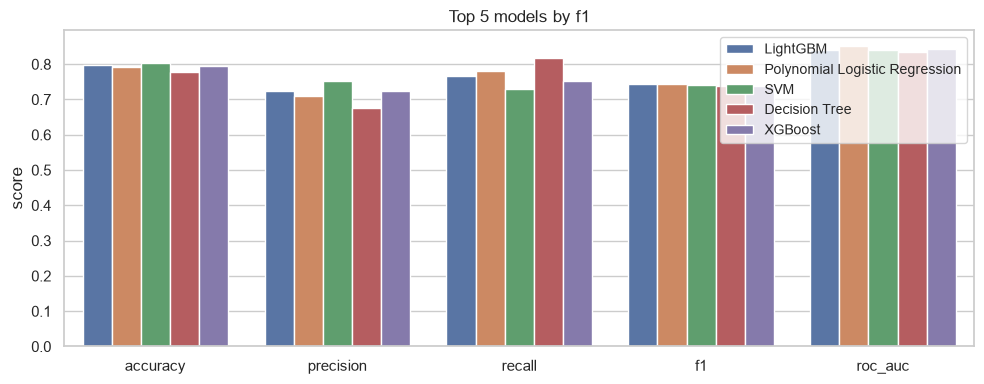

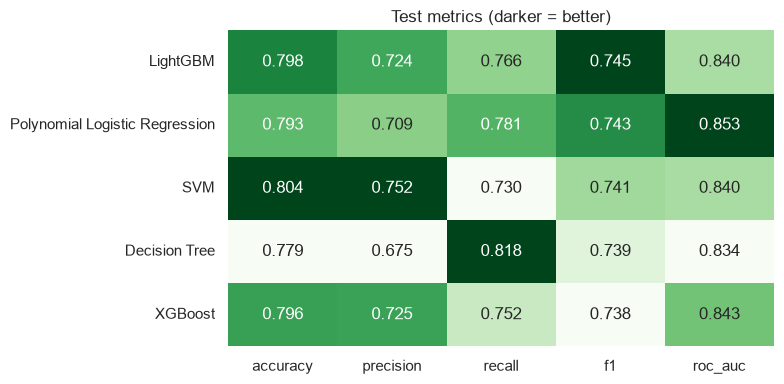

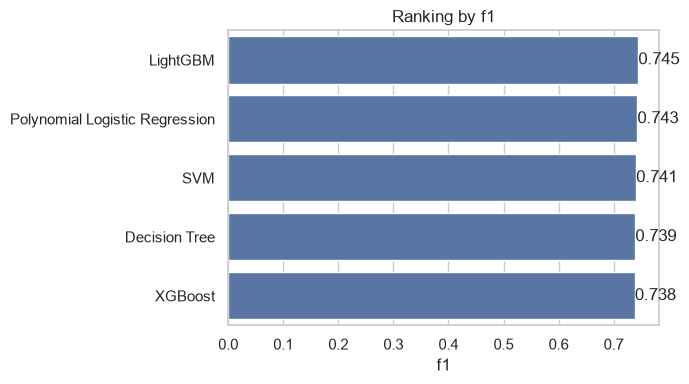

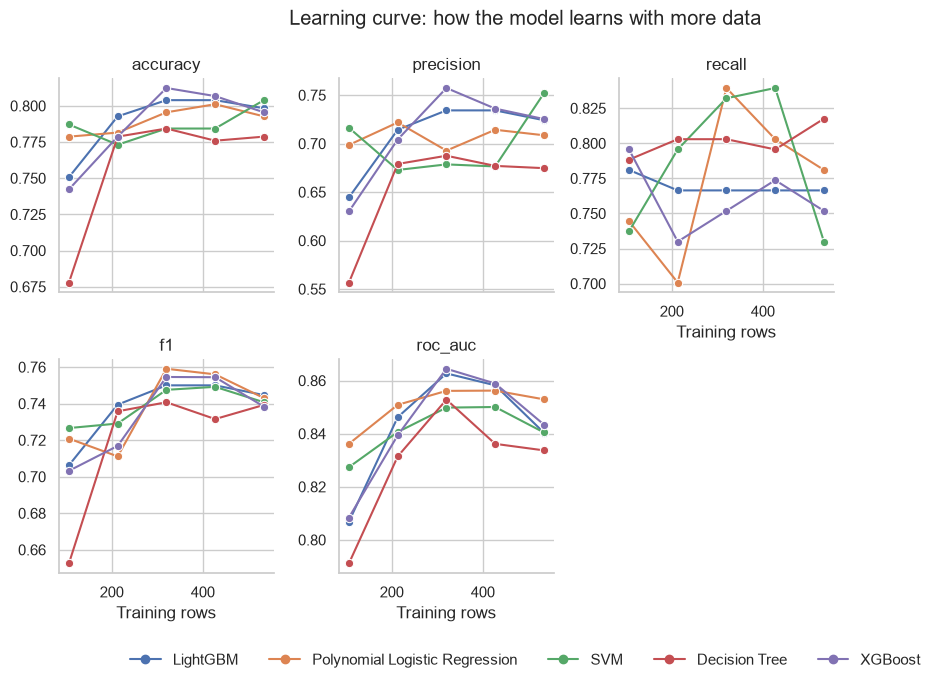

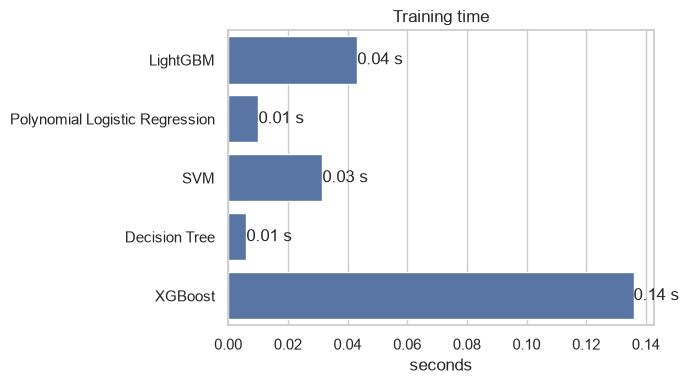

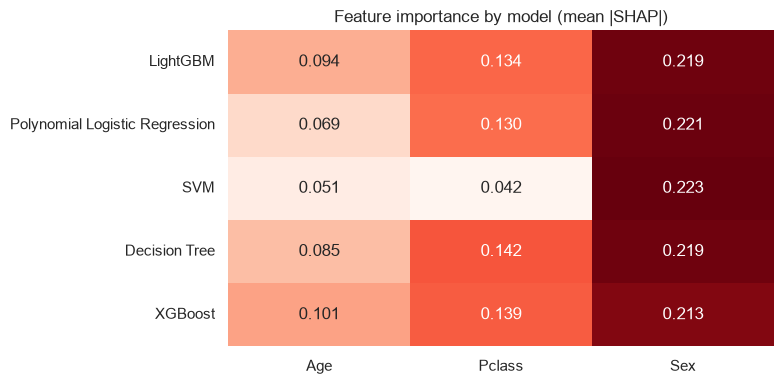

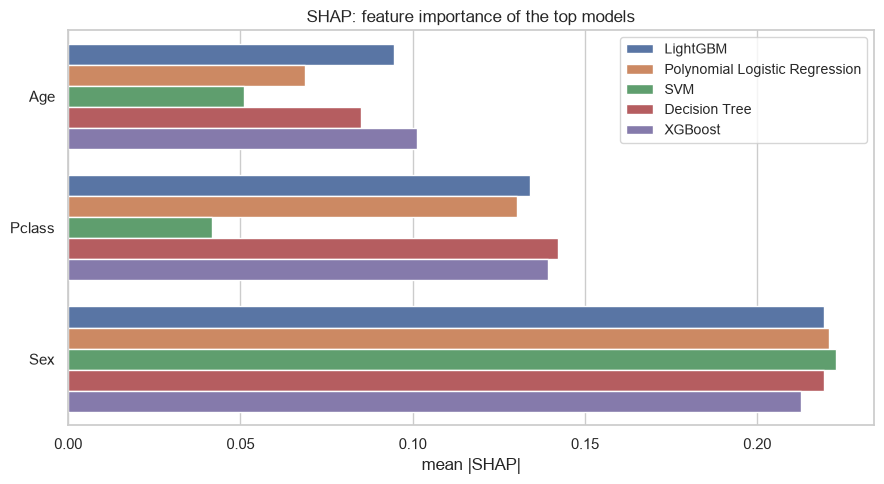

In [7]:
for chart in tracker.comparison_charts().values():
    display(chart)

## 5. Use the best model on new passengers

In [8]:
model, best = tracker.load_best_model()
print(f"Best model: {best['model']} (F1 = {best['f1']:.3f})")

passengers = pd.DataFrame(
    {
        "Pclass": [1, 3, 2, 3],
        "Sex": ["female", "male", "male", "female"],
        "Age": [29, 22, None, 5],  # missing age: the pipeline fills it with the median
    }
)
passengers["survives"] = model.predict(prepare(passengers)).astype(bool)
passengers["probability"] = model.predict_proba(prepare(passengers))[:, 1].round(3)
passengers

Best model: LightGBM (F1 = 0.745)


,Pclass,Sex,Age,survives,probability
0,1,female,29.0,True,0.954
1,3,male,22.0,False,0.100
2,2,male,NaN,False,0.173
3,3,female,5.0,True,0.874


## 6. Production: score 5 rows from the data feed

In production, a separate service does not need this notebook, the tracker or the training
code: it loads the model from MLflow **by its id** and calls `predict`. The MLflow model also
checks that the input has the right columns (its signature).

In [9]:
production_model = mlflow.pyfunc.load_model(f"models:/{best['model_id']}")

feed = df.sample(5, random_state=7)  # 5 rows arriving from the data feed
scored = feed[["Name", "Pclass", "Sex", "Age", "Survived"]].copy()
scored["predicted"] = production_model.predict(prepare(feed))
scored["correct"] = scored["predicted"] == scored["Survived"]
scored

,Name,Pclass,Sex,Age,Survived,predicted,correct
725,"Oreskovic, Mr. Luka",3,male,20.0,0,0,True
861,"Giles, Mr. Frederick Edward",2,male,21.0,0,0,True
528,"Salonen, Mr. Johan Werner",3,male,39.0,0,0,True
46,"Lennon, Mr. Denis",3,male,NaN,0,0,True
627,"Longley, Miss. Gretchen Fiske",1,female,21.0,1,1,True


## 7. Open the MLflow UI

From the project folder, run:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

and open http://127.0.0.1:5000. Each model is a run with its datasets, hyperparameters,
metrics, charts, SHAP files and the model itself. The "Top 5 comparison" run compares the best models.

Run this notebook again: every model prints `nothing changed -> skipped`.